In [1]:
import pandas as pd

In [2]:
orders = pd.read_csv(r"D:\DATA ANALYSIS\PROJECT\digikala-analysis\data\orders.csv")

orders

,ID_Order,ID_Customer,ID_Item,DateTime_CartFinalize,Amount_Gross_Order,city_name_fa,Quantity_item
0,2714054,469662,21386,2015-10-15 08:50:56.000,597982.0,محمود آباد,1.0
1,11104039,3063877,248497,2018-02-11 00:29:26.000,980000.0,خرمدره,1.0
2,4228130,3184893,50144,2016-06-14 00:30:08.000,229358.0,قرچک,1.0
3,22225624,6888562,70208,2018-09-03 14:37:19.000,16514.0,قم,1.0
4,4068771,2533490,67627,2016-05-21 11:51:02.000,133028.0,تهران,1.0
...,...,...,...,...,...,...,...
199995,12172771,4403268,445940,2018-04-03 12:07:01.000,344037.0,تهران,2.0
199996,4425393,3745774,131645,2016-07-09 19:14:09.000,600000.0,محمدیه,1.0
199997,6671889,4845514,215045,2017-03-08 23:47:06.000,450000.0,اصفهان,1.0
199998,6315995,2541418,264021,2017-02-08 14:59:39.000,193486.0,همدان,1.0


1. SALES TREND

In [3]:
orders['DateTime_CartFinalize'] = pd.to_datetime(orders['DateTime_CartFinalize'])
orders1 = orders.copy()
orders1

,ID_Order,ID_Customer,ID_Item,DateTime_CartFinalize,Amount_Gross_Order,city_name_fa,Quantity_item
0,2714054,469662,21386,2015-10-15 08:50:56,597982.0,محمود آباد,1.0
1,11104039,3063877,248497,2018-02-11 00:29:26,980000.0,خرمدره,1.0
2,4228130,3184893,50144,2016-06-14 00:30:08,229358.0,قرچک,1.0
3,22225624,6888562,70208,2018-09-03 14:37:19,16514.0,قم,1.0
4,4068771,2533490,67627,2016-05-21 11:51:02,133028.0,تهران,1.0
...,...,...,...,...,...,...,...
199995,12172771,4403268,445940,2018-04-03 12:07:01,344037.0,تهران,2.0
199996,4425393,3745774,131645,2016-07-09 19:14:09,600000.0,محمدیه,1.0
199997,6671889,4845514,215045,2017-03-08 23:47:06,450000.0,اصفهان,1.0
199998,6315995,2541418,264021,2017-02-08 14:59:39,193486.0,همدان,1.0


رشد سال به سال

In [4]:

# getting year and month
orders1['month'] = orders1['DateTime_CartFinalize'].dt.month
orders1['year'] = orders1['DateTime_CartFinalize'].dt.year

# calculating eac rows total order amount
orders1['total_sales'] = orders1['Amount_Gross_Order'] * orders1['Quantity_item']

# filtering incomplete months
filt = (orders1['DateTime_CartFinalize'] >= '2013-10-01') & (orders1['DateTime_CartFinalize'] < '2018-12-01')
orders1 = orders1[filt]

# calculating total_sales and items_sold based on month and year
yearly_growth = orders1.groupby(['year', 'month']).agg(current_sales = ('total_sales','sum'),
                                       current_items_sold = ('Quantity_item', 'sum')).reset_index()

yearly_growth = yearly_growth.sort_values(['year', 'month']).reset_index()

# shifting values 12 rows (months of the year)
yearly_growth['prev_year_items_sold'] = yearly_growth['current_items_sold'].shift(12)
yearly_growth['prev_year_sales'] = yearly_growth['current_sales'].shift(12)

# comparing sales of previous year for each month
yearly_growth['sales_diff'] = yearly_growth['current_sales'] - yearly_growth['prev_year_sales']
yearly_growth['items_diff'] = yearly_growth['current_items_sold'] - yearly_growth['prev_year_items_sold']

filt =  yearly_growth['prev_year_items_sold'].notna()

yearly_growth['sales_growth_pc'] = round((yearly_growth['current_sales'] - yearly_growth['prev_year_sales'] ) / yearly_growth['prev_year_sales'] * 100
                                          , 2)

yearly_growth['items_growth_pc'] = round((yearly_growth['current_items_sold'] - yearly_growth['prev_year_items_sold'] )/ yearly_growth['prev_year_items_sold'] * 100, 2)

yearly_growth[filt]
yearly_growth

,index,year,month,current_sales,current_items_sold,prev_year_items_sold,prev_year_sales,sales_diff,items_diff,sales_growth_pc,items_growth_pc
0,0,2013,10,4.174075e+08,77.0,NaN,NaN,NaN,NaN,NaN,NaN
1,1,2013,11,3.683478e+08,104.0,NaN,NaN,NaN,NaN,NaN,NaN
2,2,2013,12,4.409034e+08,125.0,NaN,NaN,NaN,NaN,NaN,NaN
3,3,2014,1,5.478351e+08,156.0,NaN,NaN,NaN,NaN,NaN,NaN
4,4,2014,2,7.819038e+08,195.0,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
57,57,2018,7,8.886717e+09,8056.0,5454.0,7.888091e+09,9.986267e+08,2602.0,12.66,47.71
58,58,2018,8,7.112710e+09,7944.0,5418.0,7.304086e+09,-1.913764e+08,2526.0,-2.62,46.62
59,59,2018,9,8.280815e+09,8911.0,8206.0,8.986506e+09,-7.056911e+08,705.0,-7.85,8.59
60,60,2018,10,6.763925e+09,7311.0,8182.0,8.804580e+09,-2.040655e+09,-871.0,-23.18,-10.65


رشد ماهانه

In [5]:
monthly_growth = orders1.groupby(['year', 'month']).agg(current_sales = ('total_sales', 'sum'),
                                       current_items_sold = ('Quantity_item', 'sum'))

monthly_growth = monthly_growth.sort_values(['year', 'month']).reset_index()

monthly_growth['prev_month_sales'] = monthly_growth['current_sales'].shift(1)

monthly_growth['prev_month_items_sold'] = monthly_growth['current_items_sold'].shift(1)

monthly_growth['sales_growth_pc'] = round((monthly_growth['current_sales'] - monthly_growth['prev_month_sales'] ) / monthly_growth['prev_month_sales'] * 100
                                          , 2)

monthly_growth['items_growth_pc'] = round((monthly_growth['current_items_sold'] - monthly_growth['prev_month_items_sold'] )/ monthly_growth['prev_month_items_sold'] * 100, 2)

monthly_growth

,year,month,current_sales,current_items_sold,prev_month_sales,prev_month_items_sold,sales_growth_pc,items_growth_pc
0,2013,10,4.174075e+08,77.0,NaN,NaN,NaN,NaN
1,2013,11,3.683478e+08,104.0,4.174075e+08,77.0,-11.75,35.06
2,2013,12,4.409034e+08,125.0,3.683478e+08,104.0,19.70,20.19
3,2014,1,5.478351e+08,156.0,4.409034e+08,125.0,24.25,24.80
4,2014,2,7.819038e+08,195.0,5.478351e+08,156.0,42.73,25.00
...,...,...,...,...,...,...,...,...
57,2018,7,8.886717e+09,8056.0,1.111711e+10,7917.0,-20.06,1.76
58,2018,8,7.112710e+09,7944.0,8.886717e+09,8056.0,-19.96,-1.39
59,2018,9,8.280815e+09,8911.0,7.112710e+09,7944.0,16.42,12.17
60,2018,10,6.763925e+09,7311.0,8.280815e+09,8911.0,-18.32,-17.96


فصل بندی

In [6]:
monthly_sales = monthly_growth[['year', 'month', 'current_sales', 'current_items_sold']].copy()

monthly_sales['month_start'] = pd.to_datetime(monthly_sales['year'].astype(str) + '-' + monthly_sales['month'].astype(str) + '-01')

monthly_sales = monthly_sales.sort_values('month_start').reset_index(drop=True)

# moving avg
sales = monthly_sales['current_sales']



# 6 months before to 5 months after
monthly_sales['avg1'] = sales.rolling(12).mean().shift(-5)

# 5 months before to 6 months after
monthly_sales['avg2'] = sales.rolling(12).mean().shift(-6)

# only months with complete 12 months count remain
monthly_sales['count1'] = sales.rolling(12).count().shift(-5)
monthly_sales['count2'] = sales.rolling(12).count().shift(-6)


filt = (monthly_sales['count1'] == 12) & (monthly_sales['count2'] == 12)

monthly_sales = monthly_sales[filt]

monthly_sales['trend'] = (monthly_sales['avg1'] + monthly_sales['avg2']) / 2

monthly_sales['seasonal_ratio'] = monthly_sales['current_sales']  / monthly_sales['trend']

monthly_sales['month_name'] = monthly_sales['month_start'].dt.month_name()

seasonal_index = monthly_sales.groupby([ 'month', 'month_name']).agg(seasonal_index = ('seasonal_ratio', 'mean'),
                                                 number_of_observations = ('seasonal_ratio', 'count'))

seasonal_index = seasonal_index.sort_values(['month', 'month_name']).reset_index()

seasonal_index['deviation_pct'] = round((seasonal_index['seasonal_index'] - 1) * 100, 2)
seasonal_index




,month,month_name,seasonal_index,number_of_observations,deviation_pct
0,1,January,1.004937,4,0.49
1,2,February,1.184600,4,18.46
2,3,March,1.235466,4,23.55
3,4,April,1.039124,5,3.91
4,5,May,0.963077,5,-3.69
5,6,June,0.908592,4,-9.14
6,7,July,0.952983,4,-4.70
7,8,August,0.931294,4,-6.87
8,9,September,0.939596,4,-6.04
9,10,October,0.912514,4,-8.75


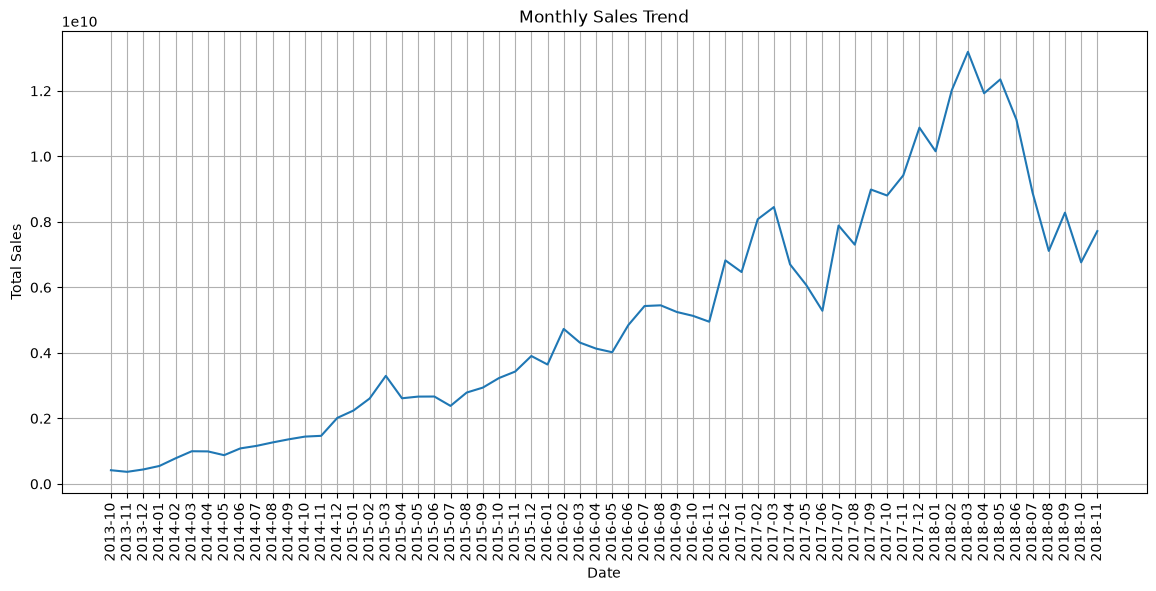

In [7]:
import matplotlib.pyplot as plt

monthly_growth['date'] = pd.to_datetime(monthly_growth['year'].astype(str) + '-' + monthly_growth['month'].astype(str))

plt.figure(figsize=(14, 6))

x = monthly_growth['date'].dt.strftime('%Y-%m')
y = monthly_growth['current_sales']

plt.plot(x, y)

plt.title('Monthly Sales Trend')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.grid()
plt.xticks(rotation=90)
plt.show()

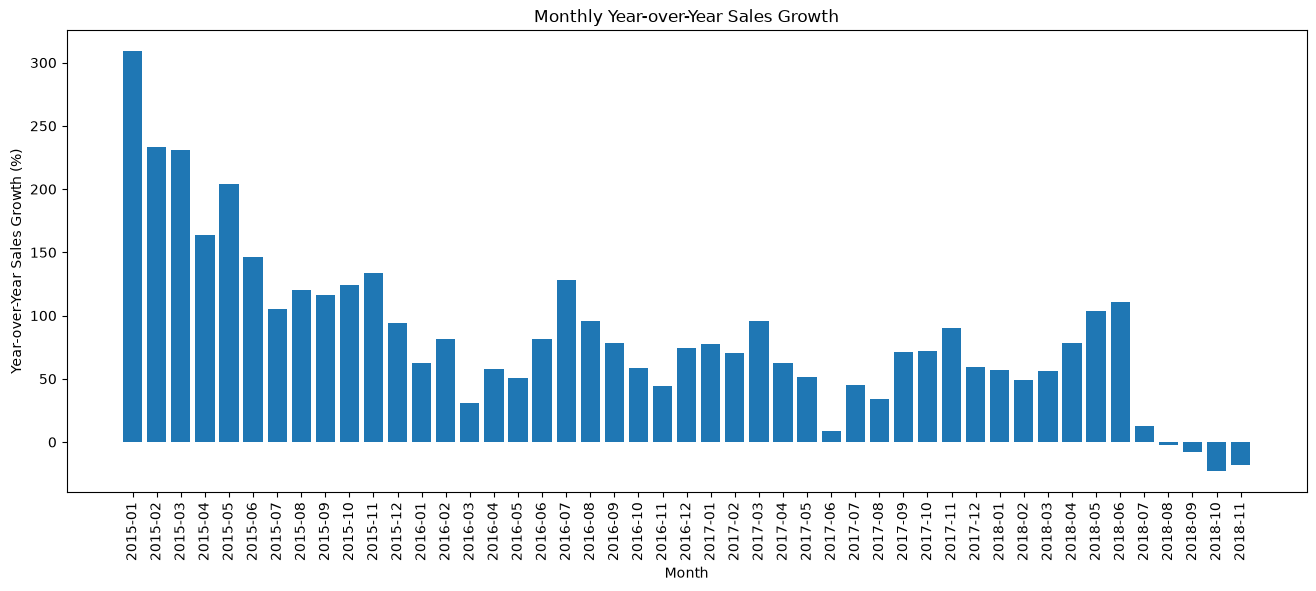

In [8]:
yearly_growth['date'] = pd.to_datetime(yearly_growth['year'].astype(str) + '-' + yearly_growth['month'].astype(str))

filt = yearly_growth['date'] > '2014-12'

x = yearly_growth.loc[filt, 'date'].dt.strftime('%Y-%m')
y = yearly_growth.loc[filt, 'sales_growth_pc']

plt.figure(figsize=(16, 6))
plt.bar(x, y)


plt.xlabel('Month')
plt.ylabel('Year-over-Year Sales Growth (%)')
plt.title('Monthly Year-over-Year Sales Growth')
plt.xticks(rotation=90)


plt.show()


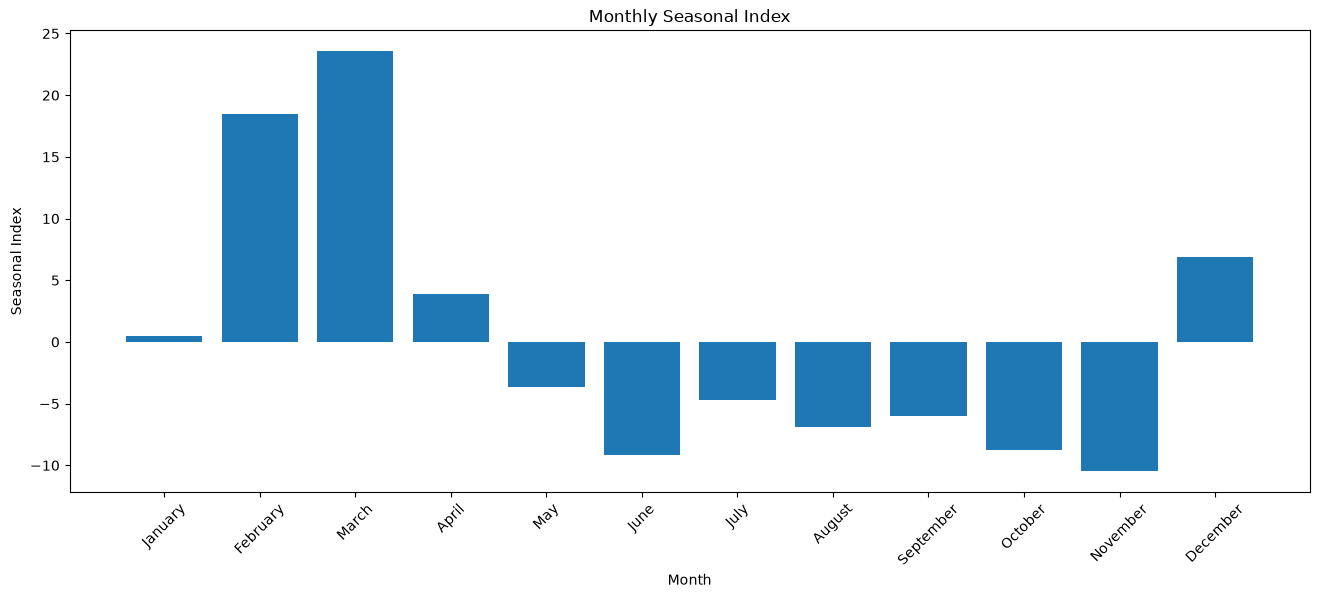

In [9]:
x = seasonal_index['month_name']
y = seasonal_index['deviation_pct']

plt.figure(figsize=(16, 6))
plt.bar(x, y)


plt.xlabel('Month')
plt.ylabel('Seasonal Index')
plt.title('Monthly Seasonal Index')
plt.xticks(rotation=45)


plt.show()


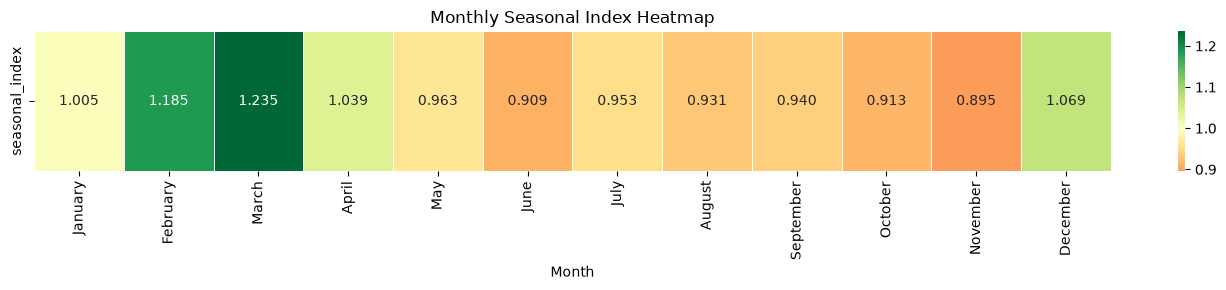

In [10]:
import seaborn as sns

heatmap_data = seasonal_index.set_index('month_name')[['seasonal_index']].T

plt.figure(figsize=(14, 3))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.3f',
    cmap='RdYlGn',
    center=1,
    linewidths=0.5  
    
)

plt.title('Monthly Seasonal Index Heatmap')
plt.xlabel('Month')
plt.ylabel('')

plt.tight_layout()
plt.show()

2. CITIES TREND

درصد هر شهر از کل سفارش

In [11]:
city_pct = orders1.groupby('city_name_fa').agg(order_num = ('ID_Order', 'nunique'))
city_pct['order_pct'] = city_pct['order_num'] / city_pct['order_num'].sum() * 100
city_pct = city_pct.sort_values('order_num', ascending=False).reset_index()

city_pct

orders1['ID_Order'].nunique()

195471

درصد تجمعی 10 شهر اول

In [12]:
city_cum_pct = city_pct.copy()
city_cum_pct = city_cum_pct.sort_values('order_pct', ascending=False).reset_index()

#city_cum_pct = city_cum_pct.head(10)

#city_cum_pct = city_cum_pct.sort_values('order_pct')

city_cum_pct['cumulative_sum'] = city_cum_pct['order_pct'].cumsum().round(2)

cities_80 = (city_cum_pct['cumulative_sum'] < 80).sum() + 1
print('Cities that make up 80% of sales = ', cities_80)

city_cum_pct = city_cum_pct.head(10)
city_cum_pct = city_cum_pct.sort_values('order_pct', ascending=False)


top10_share = city_cum_pct['order_pct'].head(10).sum()
print("Top 10 cities' share of sales = ", top10_share)


city_cum_pct 


Cities that make up 80% of sales =  22
Top 10 cities' share of sales =  72.53352159655397


,index,city_name_fa,order_num,order_pct,cumulative_sum
0,0,تهران,105868,54.160464,54.16
1,1,مشهد,5892,3.014258,57.17
2,2,اصفهان,5850,2.992771,60.17
3,3,کرج,5800,2.967192,63.13
4,4,اهواز,4222,2.159911,65.29
5,5,شیراز,3969,2.030480,67.33
6,6,رشت,3119,1.595633,68.92
7,7,تبریز,2566,1.312727,70.23
8,8,قم,2314,1.183807,71.42
9,9,کرمانشاه,2182,1.116278,72.53


دسته بندی شهرهای کمتر از 10 سفارش به سایر

In [13]:
city_cat_pct = city_pct.copy()

city_cat_pct['city_group'] = city_cat_pct['city_name_fa'].where(city_cat_pct['order_num'] >= 10, 'سایر')


city_cat_pct = city_cat_pct.groupby('city_group').agg(order_num=('order_num', 'sum')).reset_index()

city_cat_pct['order_pct'] = (city_cat_pct['order_num'] / city_cat_pct['order_num'].sum() * 100).round(2)

city_cat_pct = city_cat_pct.sort_values('order_num', ascending=False)

city_cat_pct




,city_group,order_num,order_pct
111,تهران,105868,54.16
322,مشهد,5892,3.01
33,اصفهان,5850,2.99
398,کرج,5800,2.97
46,اهواز,4222,2.16
...,...,...,...
225,سیریک,10,0.01
193,زواره,10,0.01
192,زهک,10,0.01
150,درگهان,10,0.01


سهم تهران

In [14]:
# Total unique orders per year
yearly_total = (orders1.groupby('year')['ID_Order'].nunique())

# Unique orders in Tehran per year
filt = orders1['city_name_fa'] == 'تهران'
tehran_orders = (orders1[filt].groupby('year')['ID_Order'].nunique())

# Calculate yearly share
tehran_share = (tehran_orders / yearly_total * 100).reset_index(name='tehran_share')

filt = tehran_share['year'].between(2014, 2018)
tehran_share = tehran_share[filt]

tehran_share


,year,tehran_share
1,2014,53.214453
2,2015,54.786760
3,2016,59.043213
4,2017,55.937345
5,2018,50.003432


نمودار پارتو: درصد 10 شهر اول و تجمعی آن ها

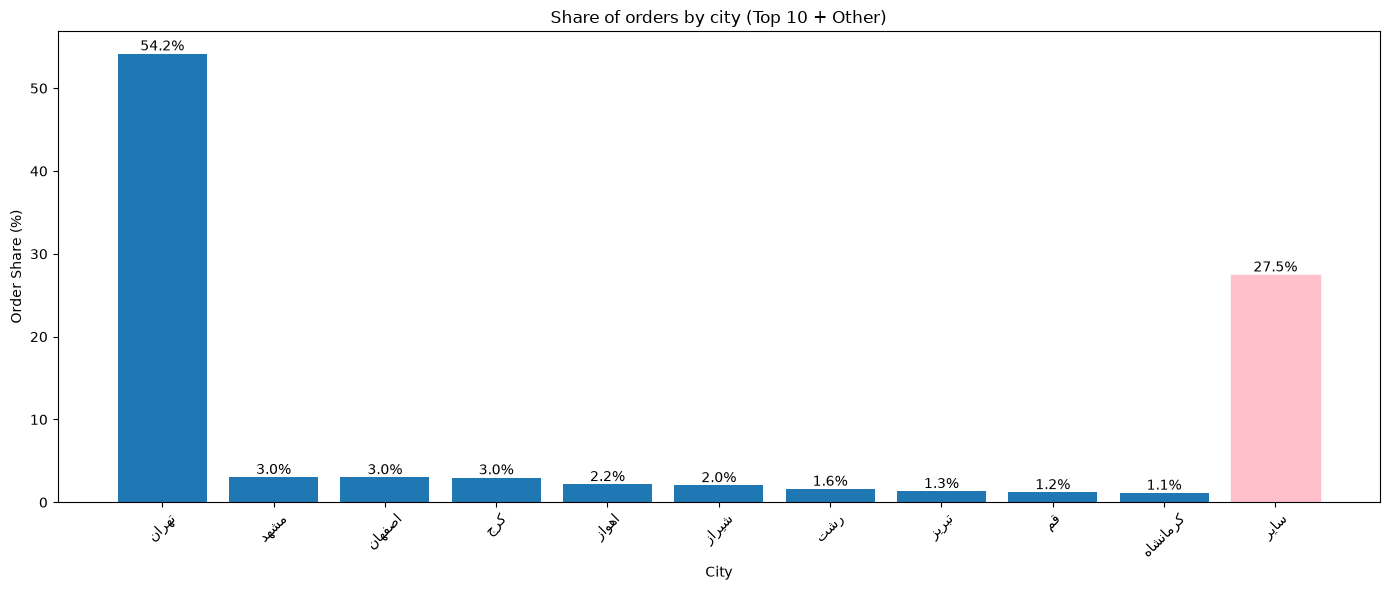

In [15]:
# catagorizing cities other than top 10 ones

top10 = city_cat_pct.head(10).copy()

other = pd.DataFrame({
    'city_group': ['سایر'],
    'order_num': [city_cat_pct['order_num'].sum() - top10['order_num'].sum()]
})

plot_data = pd.concat([top10, other], ignore_index=True)

plot_data['order_pct'] = (
    plot_data['order_num'] / plot_data['order_num'].sum() * 100
)

plt.figure(figsize=(14, 6))

x = plot_data['city_group']

y = plot_data['order_pct']

bars = plt.bar(x, y)
plt.bar_label(bars, fmt='%.1f%%')
bars[-1].set_color('pink')

plt.xlabel('City')
plt.ylabel('Order Share (%)')
plt.title('Share of orders by city (Top 10 + Other)')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

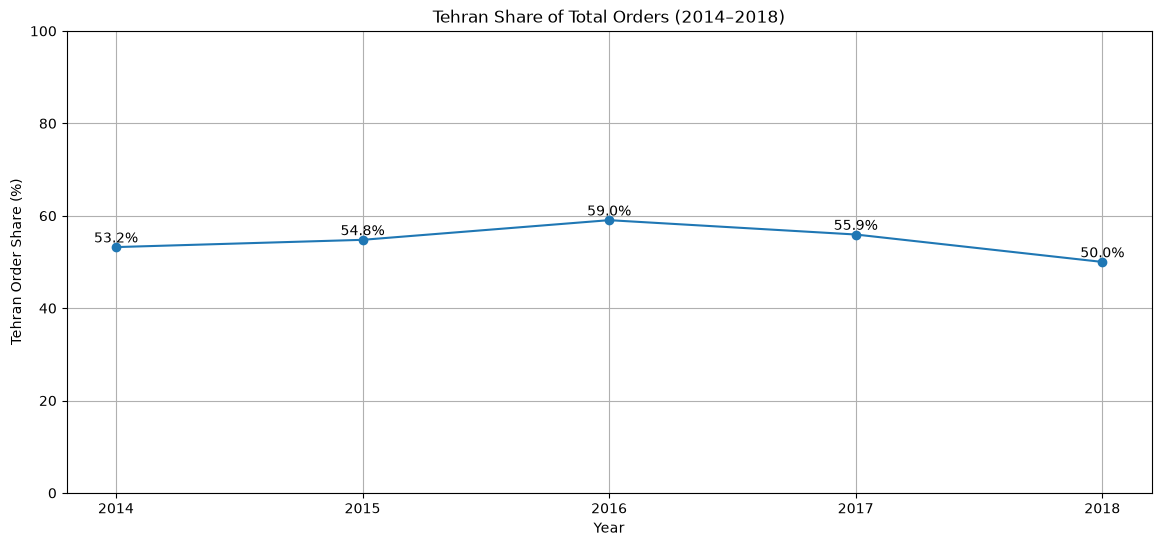

In [16]:
plt.figure(figsize=(14, 6))

x = tehran_share['year']
y = tehran_share['tehran_share']

plt.plot(x, y, marker='o')


plt.ylim(0, 100)
plt.xticks(range(2014, 2019))
plt.xlabel('Year')
plt.ylabel('Tehran Order Share (%)')
plt.title('Tehran Share of Total Orders (2014–2018)')
plt.grid()

for year, value in zip(x, y):
    plt.text(year, value + 1, f'{value:.1f}%', ha='center')

plt.show()

In [17]:
filt = city_pct['order_num'] < 10
low_order_cities = city_pct[filt]
low_order_cities

number_of_cities = len(low_order_cities)

number_of_cities

low_share = (low_order_cities['order_num'].sum() / city_pct['order_num'].sum() * 100).round(2)


print('Cities with fewer than 10 orders:', number_of_cities)
print('Long tail order share:', low_share, '%')

Cities with fewer than 10 orders: 466
Long tail order share: 0.78 %


3. ارزش سفارش

In [18]:
# mean and median

order_amounts = orders1.groupby('ID_Order').agg(order_amount = ('total_sales', 'sum'))
mean_orders_amount = order_amounts['order_amount'].mean()
median_orders_amount = order_amounts['order_amount'].median()
print('mean_orders_amount = ', mean_orders_amount)
print('median_orders_amount = ', median_orders_amount)

mean_orders_amount =  1599035.7678939586
median_orders_amount =  370000.0


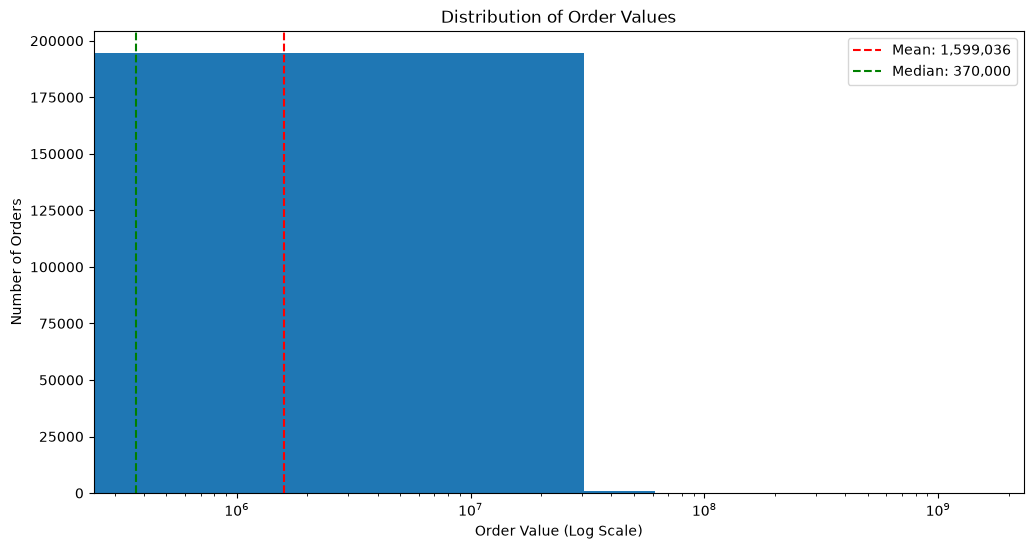

In [19]:
plt.figure(figsize=(12,6))

plt.hist(order_amounts['order_amount'], bins=50)

plt.xscale('log')

plt.axvline(mean_orders_amount, color='red', linestyle='--', label=f'Mean: {mean_orders_amount:,.0f}')
plt.axvline(median_orders_amount, color='green', linestyle='--', label=f'Median: {median_orders_amount:,.0f}')

plt.xlabel('Order Value (Log Scale)')
plt.ylabel('Number of Orders')
plt.title('Distribution of Order Values')
plt.legend()

plt.show()

In [20]:
# mean and median over the months

order_amount = orders1.groupby('ID_Order').agg(
    order_amount=('total_sales', 'sum'),
    year=('year', 'first'),
    month=('month', 'first')
).reset_index()

monthly_stats = order_amount.groupby(['year', 'month']).agg(
    mean_order_value=('order_amount', 'mean'),
    median_order_value=('order_amount', 'median')
).reset_index()

monthly_stats['date'] = pd.to_datetime(monthly_stats['year'].astype(str) + '-' + monthly_stats['month'].astype(str) + '-01')

monthly_stats

,year,month,mean_order_value,median_order_value,date
0,2013,10,5.717912e+06,2537736.0,2013-10-01
1,2013,11,4.092754e+06,1133491.0,2013-11-01
2,2013,12,3.800891e+06,1254623.0,2013-12-01
3,2014,1,3.913108e+06,1629340.0,2014-01-01
4,2014,2,5.283134e+06,897358.5,2014-02-01
...,...,...,...,...,...
57,2018,7,1.416661e+06,378000.0,2018-07-01
58,2018,8,1.195413e+06,358949.5,2018-08-01
59,2018,9,1.282257e+06,335826.0,2018-09-01
60,2018,10,1.233168e+06,380000.0,2018-10-01


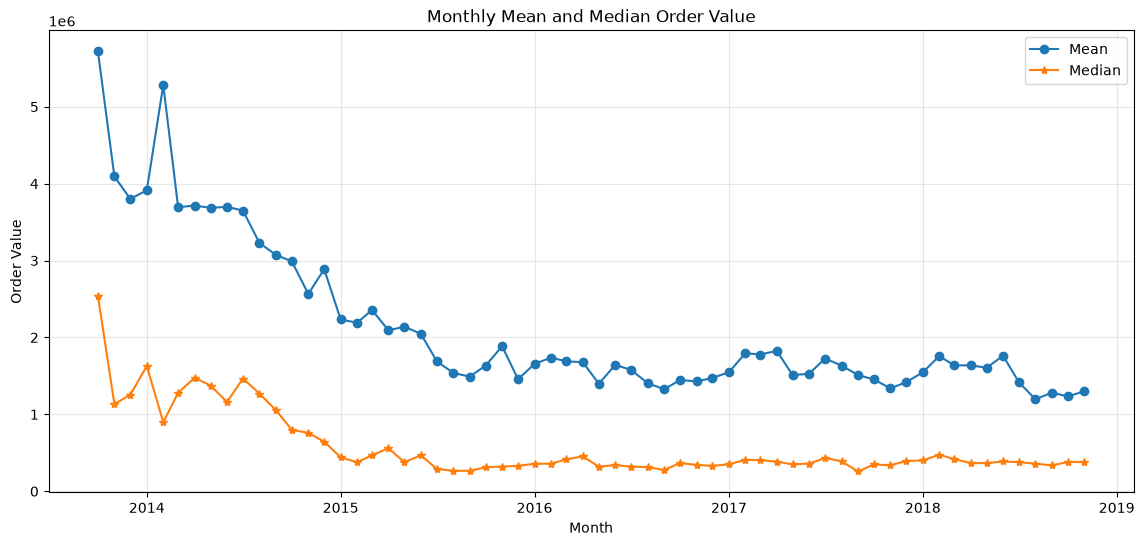

In [21]:
plt.figure(figsize=(14, 6))

x = monthly_stats['date']

y = monthly_stats['mean_order_value']

plt.plot(x, y, label = 'Mean', marker='o')

y = monthly_stats['median_order_value']

plt.plot(x, y, label = 'Median', marker='*')

plt.xlabel('Month')
plt.ylabel('Order Value')
plt.title('Monthly Mean and Median Order Value')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [ ]:
# mean and median of TEHRAN annd other cities

import numpy as np

orders1['city_group'] = np.where(orders1['city_name_fa'] == 'تهران', 'Tehran', 'Other Cities')

order_amount_city = orders1.groupby('ID_Order').agg(order_amount = ('total_sales', 'sum'), city_group = ('city_group', 'first')).reset_index()

city_stats = order_amount_city.groupby('city_group').agg(
    mean_order_value=('order_amount', 'mean'),
    median_order_value=('order_amount', 'median')
).reset_index()

city_stats




,ID_Order,order_amount,city_group
0,1003282,2500000.0,Tehran
1,1003721,14339623.0,Other Cities
2,1003814,22632075.0,Other Cities
3,1004363,7066038.0,Tehran
4,1004375,803019.0,Other Cities
...,...,...,...
195466,24531488,1500000.0,Other Cities
195467,24531562,590000.0,Other Cities
195468,24531714,1330275.0,Other Cities
195469,24531845,259000.0,Other Cities


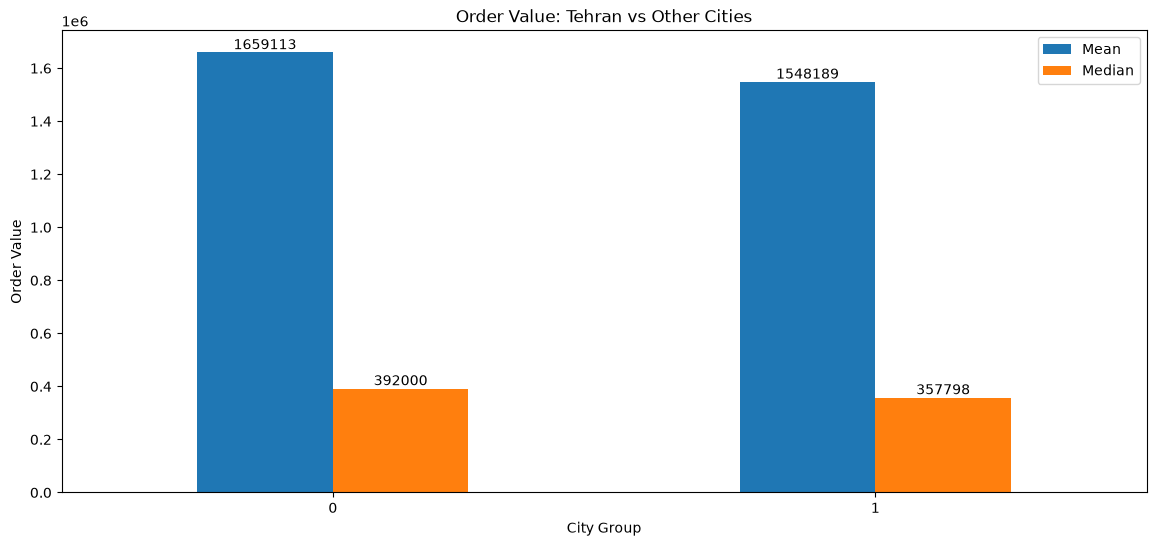

In [23]:
# city_stats  = city_stats.set_index('city_group')

ax = city_stats[['mean_order_value', 'median_order_value']].plot(kind = 'bar', figsize=(14, 6))

for i in ax.containers:
    ax.bar_label(i, fmt='%.0f')


plt.xlabel('City Group')
plt.ylabel('Order Value')
plt.title('Order Value: Tehran vs Other Cities')
plt.legend(['Mean', 'Median'])
plt.xticks(rotation = 0)


plt.show()

In [ ]:
'''

orders1.to_csv(r'D:\DATA ANALYSIS\PROJECT\digikala-analysis\data\processed\orders_filtered.csv', index=False)
monthly_growth.to_csv(r'D:\DATA ANALYSIS\PROJECT\digikala-analysis\data\processed\monthly_sales.csv', index=False)
yearly_growth.to_csv(r'D:\DATA ANALYSIS\PROJECT\digikala-analysis\data\processed\year_over_year_sales.csv', index=False)
plot_data.to_csv(r'D:\DATA ANALYSIS\PROJECT\digikala-analysis\data\processed\city_order_share.csv', index=False)
city_pct.to_csv(r'D:\DATA ANALYSIS\PROJECT\digikala-analysis\data\processed\city_analysis.csv', index=False)
tehran_share.to_csv(r'D:\DATA ANALYSIS\PROJECT\digikala-analysis\data\processed\tehran_share.csv', index=False)
order_amounts.to_csv(r'D:\DATA ANALYSIS\PROJECT\digikala-analysis\data\processed\order_value_distribution.csv', index=False)
monthly_stats.to_csv(r'D:\DATA ANALYSIS\PROJECT\digikala-analysis\data\processed\monthly_order_value.csv', index=False)
city_stats.to_csv(r'D:\DATA ANALYSIS\PROJECT\digikala-analysis\data\processed\city_order_value.csv', index=False)
seasonal_index.to_csv(r'D:\DATA ANALYSIS\PROJECT\digikala-analysis\data\processed\seasonal_index.csv', index=False)

'''